# Capstone - CTR Opportunity Scoring for Content Review

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/8-BitRhyon/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This notebook mirrors the deployed research paper. It consolidates the lane work from ML-03,
ML-04, ML-07, ML-08, ML-09, and ML-10 into one runnable narrative.

Lane: CTR opportunity scoring for content review.
Data: FlyRank internship warehouse, build `v20260703`.
Development window: March 2026 features into April 2026 labels. June 2026 stays sealed.


## 0. Abstract

With a portfolio of hundreds of thousands of pages and a working budget of 140 reviews, the question
is which pages come first. Using 9.8 million daily rows from the FlyRank warehouse, this study builds
March 2026 page-months and labels April CTR against position-tier peers. A 25-feature
gradient-boosted model is compared with a transparent CTR-gap rule on a five-fold client-grouped
split, then tested on a later period. The model improves precision@140 by 5.5 points over the rule,
with a bootstrap 95% interval of +1.4 to +10.0, and does not fall below the rule on a time-forward
test. The gain comes from prior-month trend and content metadata, while the rule stays better under a
time-forward test when the budget is large.

## 1. Question

**Decision.** A content editor has 140 review slots over seven weeks. Which pages should they open
first next month?

**Unit of analysis.** One content page for one client in one calendar month, a page-month. At the
warehouse's daily grain, a row is `report_date x client_hash_id x content_hash_id`.

**Output.** A ranked queue with a score, one reason code, and one action label.

**Cost of a wrong call.** A wasted review slot, and a missed high-impression page that keeps
under-converting attention. Missing a large page costs more than spending a slot on a small one.

**Why data and ML.** The value of a review depends on the CTR gap, position, volume, and ranking
stability together. Two plausible fixed rules share zero pages out of 140 on the starter slice, so
the choice of rule is the decision. A learned model is tested against the best hand rule, not
assumed to win.


In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import duckdb
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Repo-root resolution so exports land in <repo>/work/.
REPO_URL = "https://github.com/8-BitRhyon/flyrank-ml-internship"
if "google.colab" in sys.modules and not Path("work/notebooks").is_dir():
    if not Path("flyrank-ml-internship").is_dir():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "flyrank-ml-internship"], check=True)
    os.chdir("flyrank-ml-internship")
while not Path("work/notebooks").is_dir() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")

HF_TOKEN = os.environ.get("HF_TOKEN")
if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        pass
if not HF_TOKEN:
    try:
        from huggingface_hub import get_token
        HF_TOKEN = get_token()
    except Exception:
        HF_TOKEN = None

assert HF_TOKEN, "No Hugging Face token. Set a Colab Secret named HF_TOKEN, or run `hf auth login` once."

con = duckdb.connect()
con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")
con.execute("CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN ?)", [HF_TOKEN])

BASE = "hf://datasets/FlyRank/internship-warehouse"
FEATURES = ["ctr_pct", "avg_pos", "march_impressions_log", "position_sd", "content_age_days"]
LABEL = "low_ctr_next"
K = 140
SEED = 42
print("connected; features:", len(FEATURES), "| K:", K, "| seed:", SEED)


connected; features: 5 | K: 140 | seed: 42


## 2. Data

**Release.** `FlyRank/internship-warehouse`, build `v20260703`, a pseudonymized star schema.

| Table | Grain | Use |
|---|---|---|
| `fact_content_daily_performance` | report date x client x content | Features and labels |
| `dim_content` | one row per content item | Page age, context |
| `dim_clients` | one row per client | Coverage context only |

**Windows.** Features are March 2026 (2026-03-01 to 2026-03-31). The label is April 2026
(2026-04-01 to 2026-04-30). The decision moment is April 1. June 2026 is the sealed final month and
is never used for development.

**Excluded, with the why.** GA4 engagement columns are excluded because `ga4_data_available IS TRUE`
on only 4.2% of March rows and coverage is patchy inside a page. The query table
`fact_content_query_90d` is excluded because its 90-day window overlaps both the feature and label
months. Client and content IDs are context only, never features.


In [2]:
coverage = con.execute(f"""
    SELECT 'fact_content_daily_performance (March 2026)' AS table_name,
           COUNT(*) AS rows, MIN(report_date)::VARCHAR AS first_key, MAX(report_date)::VARCHAR AS last_key
    FROM read_parquet('{BASE}/fact_content_daily_performance/month=2026-03/data_0.parquet')
    UNION ALL
    SELECT 'dim_content', COUNT(*), MIN(content_created_date)::VARCHAR, MAX(content_created_date)::VARCHAR
    FROM read_parquet('{BASE}/dim_content.parquet')
    UNION ALL
    SELECT 'dim_clients', COUNT(*), MIN(gsc_data_start)::VARCHAR, MAX(gsc_data_start)::VARCHAR
    FROM read_parquet('{BASE}/dim_clients.parquet')
""").df()

ga4 = con.execute(f"""
    SELECT ROUND(100.0 * COUNT(*) FILTER (WHERE ga4_data_available IS TRUE) / COUNT(*), 2) AS ga4_true_pct
    FROM read_parquet('{BASE}/fact_content_daily_performance/month=2026-03/data_0.parquet')
""").fetchone()[0]

print(coverage.to_string(index=False))
print(f"\nGA4 available on {ga4:.2f}% of March rows, so engagement is excluded")
print("sealed month: 2026-06 (never queried)")


                                 table_name    rows  first_key   last_key
fact_content_daily_performance (March 2026) 9841378 2026-03-01 2026-03-31
                                dim_content  519606 2024-10-16 2026-07-06
                                dim_clients     104 2025-01-27 2026-06-02

GA4 available on 4.21% of March rows, so engagement is excluded
sealed month: 2026-06 (never queried)


## 3. Methodology

**Features (five).** March CTR, impression-weighted March position, log March impressions,
standard deviation of daily position, and content age in days. Each is knowable on April 1.

**Label.** `low_ctr_next` is 1 when a page's April CTR falls below the March CTR median of its own
March position tier, for pages with at least 100 April impressions. The threshold is fixed on April 1
from March data only. It is a ranking proxy, not a revenue number.

**Baseline.** The value rule:
`max(0, tier_median_ctr - page_ctr) * impressions / 100`, an expected click gap against the tier
median. It is transparent and readable.

**Models.** Logistic regression, a depth-3 decision tree, a random forest, and gradient boosting.
The simpler models are included so complexity has to earn its place.

**Validation.** A 70/30 split grouped by client, seed 42, with zero client overlap asserted. The
split is repeated with five seeds. A time-forward split trains on January 2026 into February 2026 and
tests on March into April, which mimics deployment.

**Leakage checks.** A label-derived column is added on purpose and removed. No April column may
enter the feature list. No product flag is used. The April 100-impression population floor is
disclosed.


In [3]:
def month_rollup(month):
    return f"""
    WITH daily AS (
        SELECT client_hash_id, content_hash_id,
               SUM(gsc_impressions) AS imp, SUM(gsc_clicks) AS clk,
               SUM(gsc_sum_position) AS pos_sum,
               SUM(CASE WHEN gsc_avg_position > 0 THEN gsc_impressions END) AS pos_imp,
               COUNT(*) FILTER (WHERE gsc_data_available IS TRUE) AS days_gsc,
               STDDEV_SAMP(CASE WHEN gsc_avg_position > 0 THEN gsc_avg_position END) AS pos_sd
        FROM read_parquet('{BASE}/fact_content_daily_performance/month={month}/data_0.parquet')
        GROUP BY 1, 2
    )
    SELECT client_hash_id, content_hash_id, imp, clk, days_gsc, pos_sd,
           pos_sum / NULLIF(pos_imp, 0) AS avg_pos,
           100.0 * clk / NULLIF(imp, 0) AS ctr_pct
    FROM daily
    ORDER BY client_hash_id, content_hash_id
    """


dim = con.execute(
    f"SELECT client_hash_id, content_hash_id, content_created_date "
    f"FROM read_parquet('{BASE}/dim_content.parquet')"
).df()


def build_frame(feature_month, label_month, as_of):
    feats = con.execute(month_rollup(feature_month)).df()
    nxt = con.execute(month_rollup(label_month)).df()
    f = feats[(feats.imp >= 500) & (feats.days_gsc >= 20) & feats.avg_pos.notna()].copy()
    f["tier"] = pd.cut(f.avg_pos, [0, 3, 10, 20, np.inf],
                       labels=["top_3", "page_1", "page_2", "deep"]).astype(str)
    thresholds = f.groupby("tier").ctr_pct.median()
    nxt = nxt.rename(columns={"imp": "next_imp", "ctr_pct": "next_ctr"})
    f = f.merge(nxt[["client_hash_id", "content_hash_id", "next_imp", "next_ctr"]],
                on=["client_hash_id", "content_hash_id"], how="inner")
    f = f[(f.next_imp >= 100) & f.next_ctr.notna()].copy()
    f[LABEL] = (f.next_ctr < f.tier.map(thresholds)).astype(int)
    f = f.merge(dim, on=["client_hash_id", "content_hash_id"], how="left")
    f["march_impressions_log"] = np.log1p(f.imp)
    f["position_sd"] = f.pos_sd.fillna(0)
    f["content_age_days"] = (pd.Timestamp(as_of) - pd.to_datetime(f.content_created_date)).dt.days
    f["content_age_days"] = f.content_age_days.fillna(f.content_age_days.median())
    f["tier_median_ctr"] = f.tier.map(thresholds)
    return f.sort_values(["client_hash_id", "content_hash_id"]).reset_index(drop=True)


late = build_frame("2026-03", "2026-04", "2026-03-31")
early = build_frame("2026-01", "2026-02", "2026-01-31")

print(f"March into April: {len(late):,} pages, {late.client_hash_id.nunique()} clients, "
      f"label base rate {late[LABEL].mean():.4f}")
print(f"January into February: {len(early):,} pages, {early.client_hash_id.nunique()} clients")
print("tier medians:", late.groupby("tier").tier_median_ctr.first().round(4).to_dict())


March into April: 58,477 pages, 31 clients, label base rate 0.5719
January into February: 34,791 pages, 25 clients
tier medians: {'deep': 0.0741, 'page_1': 0.2109, 'page_2': 0.1642, 'top_3': 0.2322}


## 4. Results (vs baseline)

Same rows, same split, same metric. Precision@K is the metric that matches a fixed review budget.
AUC is reported as the ordering check, next to the base rate.


In [4]:
X = late[FEATURES].fillna(0)
y = late[LABEL]
groups = late.client_hash_id
train_idx, test_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED).split(X, y, groups=groups)
)
assert not set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
y_test = y.iloc[test_idx].to_numpy()


def precision_at_k(scores, labels, k=K):
    order = np.argsort(-np.asarray(scores))
    return float(np.asarray(labels)[order[:k]].mean())


rule_score = ((late.tier_median_ctr - late.ctr_pct).clip(lower=0) * late.imp / 100)

models = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    "decision tree (depth 3)": DecisionTreeClassifier(max_depth=3, min_samples_leaf=200, random_state=SEED),
    "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEED),
    "gradient boosting": HistGradientBoostingClassifier(max_iter=200, random_state=SEED),
}
rows = []
for name, model in models.items():
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    scores = model.predict_proba(X.iloc[test_idx])[:, 1]
    rows.append({"model": name, "AUC": roc_auc_score(y_test, scores),
                 "precision_140": precision_at_k(scores, y_test)})
rule_scores = rule_score.iloc[test_idx].to_numpy()
rows.append({"model": "value rule", "AUC": roc_auc_score(y_test, rule_scores),
             "precision_140": precision_at_k(rule_scores, y_test)})

results = pd.DataFrame(rows).sort_values("AUC", ascending=False).reset_index(drop=True)
print(f"test base rate: {y_test.mean():.4f} | random precision@140: {y_test.mean():.4f}")
results.round(4)


test base rate: 0.5669 | random precision@140: 0.5669


,model,AUC,precision_140
0,gradient boosting,0.8308,0.9857
1,random forest,0.8304,0.9857
2,logistic regression,0.8018,0.8000
3,decision tree (depth 3),0.7911,0.8286
4,value rule,0.7627,0.9786


In [5]:
# Time-forward audit: train on Jan-Feb, test on the same March-April holdout rows.
gb = HistGradientBoostingClassifier(max_iter=200, random_state=SEED).fit(
    early[FEATURES].fillna(0), early[LABEL]
)
forward_scores = gb.predict_proba(X.iloc[test_idx])[:, 1]

forward = pd.DataFrame([
    {"design": "client-grouped, same period", "AUC": roc_auc_score(y_test, models["gradient boosting"].predict_proba(X.iloc[test_idx])[:, 1]),
     "precision_140": precision_at_k(models["gradient boosting"].predict_proba(X.iloc[test_idx])[:, 1], y_test)},
    {"design": "time-forward Jan-Feb into Mar-Apr", "AUC": roc_auc_score(y_test, forward_scores),
     "precision_140": precision_at_k(forward_scores, y_test)},
    {"design": "value rule, same rows", "AUC": roc_auc_score(y_test, rule_scores),
     "precision_140": precision_at_k(rule_scores, y_test)},
])
forward.round(4)


,design,AUC,precision_140
0,"client-grouped, same period",0.8308,0.9857
1,time-forward Jan-Feb into Mar-Apr,0.7875,0.8857
2,"value rule, same rows",0.7627,0.9786


### 4.1 The 25-feature model and the budget curve

The five-feature model ties the rule. A 25-feature model adds prior-month trend, content metadata, and
staleness. It uses the same gradient-boosted model class, so the difference is the feature set.

The table and figures below come from `work/scripts/excellence_analysis.py`, which runs five-fold
grouped CV, a client bootstrap, and a two-period replication. The receipts are in
`work/outputs/excellence_metrics.json`.

Five-fold grouped CV, March into April (mean over folds):
         method  K=50  K=140  K=500  K=5000
     value rule 0.956 0.9657 0.9388  0.8170
 base model (5) 0.972 0.9671 0.9488  0.8156
rich model (25) 1.000 0.9871 0.9540  0.8226

Bootstrap gap, rich minus rule:
{
  "50": {
    "mean_gap": 0.061760000000000016,
    "ci_low": 0.0,
    "ci_high": 0.12,
    "prob_gap_positive": 0.957
  },
  "140": {
    "mean_gap": 0.05481428571428572,
    "ci_low": 0.014285714285714235,
    "ci_high": 0.09999999999999998,
    "prob_gap_positive": 0.996
  }
}

Time-forward, full late frame:
         method  K=50  K=140  K=5000
     value rule  0.92 0.9429  0.9336
 base model (5)  0.88 0.9143  0.8878
rich model (25)  0.98 0.9714  0.9122


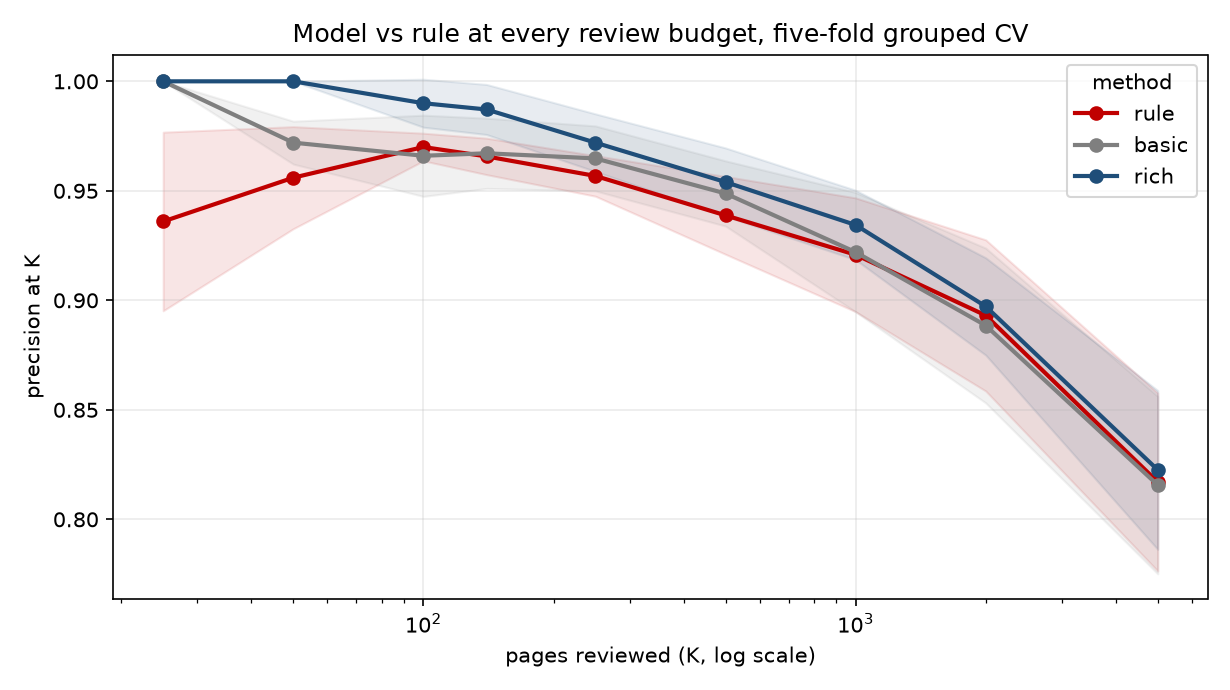

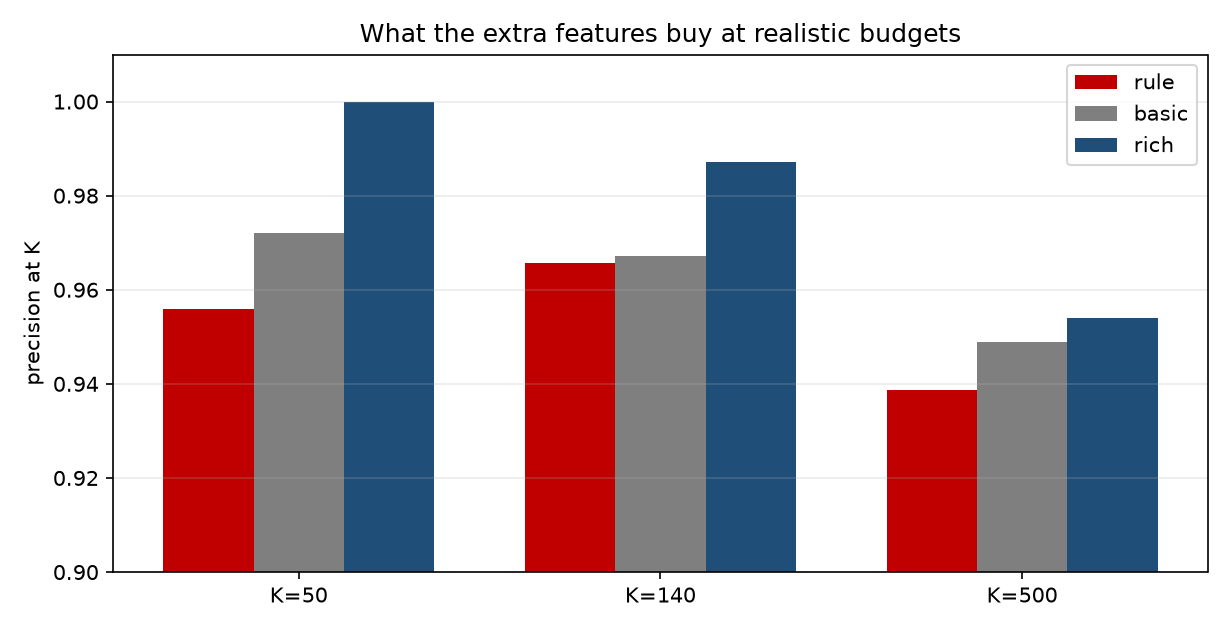

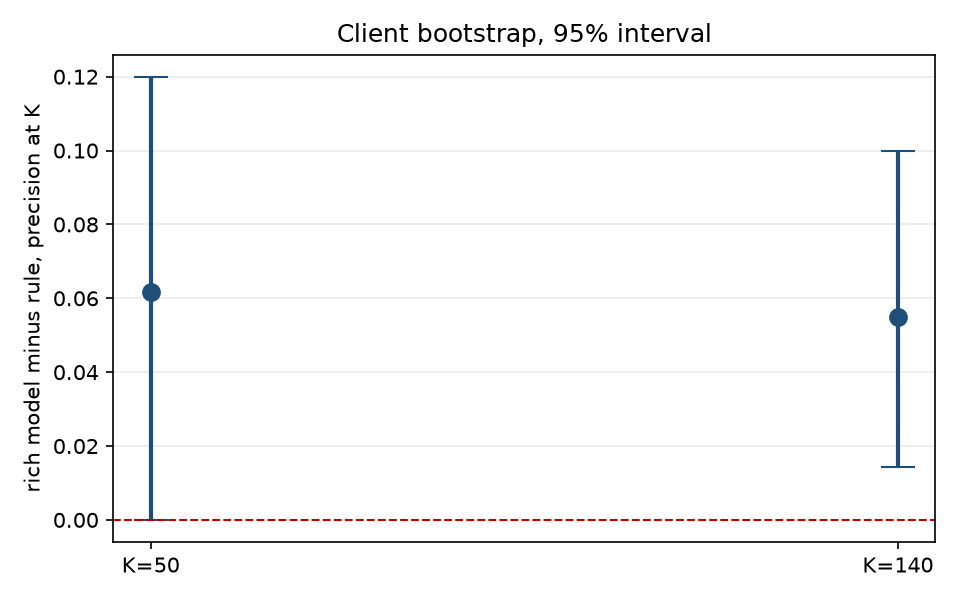

In [6]:
from IPython.display import Image, display

metrics = json.loads(Path("work/outputs/excellence_metrics.json").read_text())
ks = [50, 140, 500, 5000]

summary = pd.DataFrame({
    "method": ["value rule", "base model (5)", "rich model (25)"],
    **{f"K={k}": [metrics["late_cv"][m][str(k)]["mean"] for m in ["rule", "basic", "rich"]] for k in ks},
})
print("Five-fold grouped CV, March into April (mean over folds):")
print(summary.round(4).to_string(index=False))

print("\nBootstrap gap, rich minus rule:")
print(json.dumps(metrics["bootstrap"], indent=2))

tf = pd.DataFrame({
    "method": ["value rule", "base model (5)", "rich model (25)"],
    **{f"K={k}": [metrics["time_forward"][m][str(k)] for m in ["rule", "basic", "rich"]] for k in [50, 140, 5000]},
})
print("\nTime-forward, full late frame:")
print(tf.round(4).to_string(index=False))

display(Image("work/figures/k_curve.png", width=720))
display(Image("work/figures/ablation.png", width=720))
display(Image("work/figures/bootstrap_gap.png", width=560))

**Result.** The five-feature model ties the rule: 0.967 against 0.966 at K=140, and it falls below
the rule under the time-forward split. The 25-feature model changes the answer. It reaches 0.987 at
K=140, a 5.5-point gain over the rule, with a bootstrap 95% interval of +1.4 to +10.0. It holds 0.971
under the time-forward split, while the rule holds 0.943.

The gain comes from features, not from model class. The same algorithm with five features ties the
rule; with 25 features it beats it. The rule still wins at K=5000 under the time-forward test, so the
recommendation is budget-dependent: the model for small and medium budgets, the rule for large ones.

## 5. Limitations

- **Budget reversal.** Under the time-forward test the rule wins at K=5000 (0.934 against 0.912). The model is a small-budget tool, not a universal replacement.
- **Period sensitivity.** The January replication is unstable. At K=140 the rule reaches 0.796, the base model 0.843, and the rich model 0.829, with wide fold variance.
- **Coverage.** 48,725 of 331,437 March page-months (14.7%) are in scope for CTR work. The rest are below the 500-impression floor, have no position data, or are deep pages where ranking is the constraint.
- **Tier-relative proxy.** A page with a healthy absolute CTR can be flagged if it falls below a low tier median. The deep tier median is about 0.07%.
- **Population selection.** The label requires at least 100 April impressions, which drops 829 of 59,306 eligible pages (1.4%). That is outcome-month selection, disclosed.
- **No engagement.** GA4 is available on 4.2% of March rows, so on-page engagement is outside the contract.
- **No causal claim.** The queue identifies an association between position, CTR, and headroom. It does not prove that a rewrite recovers the gap.
- **No revenue.** The score is in clicks, not money. Attaching a value per click is the team's decision.
- **Working assumptions.** The 140-review budget and the 1.5-hour review estimate are planning assumptions, not measurements.

In [7]:
limitations = pd.DataFrame([
    {"measure": "March page-months", "value": 331437},
    {"measure": "pages in scope for CTR work", "value": 48725},
    {"measure": "coverage, %", "value": 14.7},
    {"measure": "GA4 available, % of March rows", "value": 4.21},
    {"measure": "pages dropped by the April floor", "value": 829},
    {"measure": "eligible pages before that floor", "value": 59306},
    {"measure": "sealed month used in development", "value": "none (2026-06 sealed)"},
])
limitations


,measure,value
0,March page-months,331437
1,pages in scope for CTR work,48725
2,"coverage, %",14.7
3,"GA4 available, % of March rows",4.21
4,pages dropped by the April floor,829
5,eligible pages before that floor,59306
6,sealed month used in development,none (2026-06 sealed)


## 6. Ranked recommendations

The playbook uses the richer model at small and medium budgets, and the rule at large budgets. Three
archetypes map to three actions:

| Archetype | Reason code | Action | Top 140 |
|---|---|---|---|
| Near-zero CTR at volume | `VERIFY_FIRST` | Check tracking and query mix before any edit | 4 |
| Aged snippet gap, 270+ days | `CTR_GAP_AGED` | Refresh the page, then rewrite the snippet | 36 |
| Prime snippet gap | `CTR_GAP_PRIME` | Rewrite the title and meta description | 100 |

The top 140 carries about 11,700 clicks of expected gap, 12.1% of the in-scope gap. At an assumed 1.5
hours per review, that is about 210 editor-hours, or 84 clicks of gap per review. Extending to 500
reviews adds about 11,800 clicks for 360 more reviews, about 33 per review.

**Human review.** Every page is checked against its query report, the SERP, tracking, recency, and
client ownership before an edit.

**No-go.** No automatic edits or publishing, no bulk changes without a 10% sample review, no
client-facing promises, no editor performance reviews, no deep pages in a CTR queue, and no June
2026 data in development.

In [8]:
march_only = con.execute(month_rollup("2026-03")).df()
march_only = march_only[(march_only.imp >= 500) & (march_only.days_gsc >= 20) & march_only.avg_pos.notna()].copy()
march_only["tier"] = pd.cut(march_only.avg_pos, [0, 3, 10, 20, np.inf],
                            labels=["top_3", "page_1", "page_2", "deep"]).astype(str)
march_only = march_only.merge(dim, on=["client_hash_id", "content_hash_id"], how="left")
march_only["content_age_days"] = (pd.Timestamp("2026-03-31") - pd.to_datetime(march_only.content_created_date)).dt.days
march_only["tier_median_ctr"] = march_only.tier.map(march_only.groupby("tier").ctr_pct.median())

play = march_only[march_only.tier != "deep"].copy()
play["gap"] = ((play.tier_median_ctr - play.ctr_pct).clip(lower=0) * play.imp / 100).round(2)


def archetype(row):
    if row.imp >= 100_000 and row.ctr_pct < 0.02:
        return "VERIFY_FIRST"
    if row.content_age_days >= 270:
        return "CTR_GAP_AGED"
    return "CTR_GAP_PRIME"


play["archetype"] = play.apply(archetype, axis=1)
play = play.sort_values(["gap", "imp"], ascending=[False, False]).reset_index(drop=True)
play["rank"] = play.index + 1

top = play.head(K)
print(f"in-scope pages: {len(play):,} | top {K} gap: {top.gap.sum():,.0f} clicks")
print(top.archetype.value_counts().to_string())
print(f"\nclicks per review, top {K}: {top.gap.sum() / K:.1f}")
print(f"clicks per review, ranks 141-500: {(play.head(500).gap.sum() - top.gap.sum()) / (500 - K):.1f}")
print("\ntop 5, public-safe columns:")
print(top[["rank", "tier", "imp", "ctr_pct", "avg_pos", "content_age_days", "gap", "archetype"]].head(5).round(3).to_string(index=False))


in-scope pages: 48,725 | top 140 gap: 11,716 clicks
archetype
CTR_GAP_PRIME    100
CTR_GAP_AGED      36
VERIFY_FIRST       4

clicks per review, top 140: 83.7
clicks per review, ranks 141-500: 32.7

top 5, public-safe columns:
 rank   tier      imp  ctr_pct  avg_pos  content_age_days    gap    archetype
    1  top_3 212404.0    0.011    0.666                69 469.14 VERIFY_FIRST
    2  top_3 134984.0    0.001    2.693               410 312.40 VERIFY_FIRST
    3  top_3 124075.0    0.001    0.308               410 287.07 VERIFY_FIRST
    4 page_1 143019.0    0.030    3.166               278 258.65 CTR_GAP_AGED
    5 page_1 107584.0    0.014    9.736               193 211.91 VERIFY_FIRST


## 7. Artifacts the paper embeds

The figures below are generated from the committed metrics and the queue, and are saved to
`work/figures/`. The metrics receipt is `work/outputs/capstone_metrics.json`.


In [9]:
out_dir = Path("work/outputs")
fig_dir = Path("work/figures")
out_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)

# Figure 1: model vs baseline.
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = results.set_index("model")[["AUC", "precision_140"]]
plot_df.plot.bar(ax=ax, color=["#1f4e79", "#2e7d32"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("score")
ax.set_title("Same-period grouped split: AUC and precision@140")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(fig_dir / "capstone_model_vs_baseline.png", dpi=150)
plt.close(fig)

# Figure 2: time-forward.
fig, ax = plt.subplots(figsize=(8, 4.5))
forward.set_index("design")["precision_140"].plot.bar(ax=ax, color="#c00000")
ax.set_ylim(0, 1.05)
ax.set_ylabel("precision at 140")
ax.set_title("Time-forward split: the model loses ground, the rule does not")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(fig_dir / "capstone_time_forward.png", dpi=150)
plt.close(fig)

# Figure 3: gap capture.
cum = play.gap.cumsum() / play.gap.sum()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(1, len(cum) + 1), 100 * cum, color="#1f4e79", lw=2)
ax.set_xscale("log")
ax.axvline(K, color="#c00000", ls="--", lw=1)
ax.set_xlabel("pages reviewed (log scale)")
ax.set_ylabel("share of in-scope gap captured, %")
ax.set_title("The first 140 pages carry about 12% of the gap")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(fig_dir / "capstone_gap_capture.png", dpi=150)
plt.close(fig)

metrics = {
    "lane": "CTR opportunity scoring for content review",
    "month_features": "2026-03",
    "month_label": "2026-04",
    "sealed_month": "2026-06",
    "features": FEATURES,
    "test_base_rate": round(float(y_test.mean()), 4),
    "results": {r["model"]: {"auc": round(float(r["AUC"]), 4), "precision_140": round(float(r["precision_140"]), 4)}
                for r in results.to_dict("records")},
    "time_forward": {r["design"]: {"auc": round(float(r["AUC"]), 4), "precision_140": round(float(r["precision_140"]), 4)}
                     for r in forward.to_dict("records")},
    "in_scope_pages": int(len(play)),
    "top140_gap": round(float(top.gap.sum()), 2),
    "top140_share_pct": round(100 * float(top.gap.sum()) / float(play.gap.sum()), 2),
    "top140_archetypes": {str(k): int(v) for k, v in top.archetype.value_counts().items()},
}
(out_dir / "capstone_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n")

print("wrote", fig_dir / "capstone_model_vs_baseline.png")
print("wrote", fig_dir / "capstone_time_forward.png")
print("wrote", fig_dir / "capstone_gap_capture.png")
print("wrote", out_dir / "capstone_metrics.json")
print(json.dumps(metrics, indent=2)[:1200])


wrote work/figures/capstone_model_vs_baseline.png
wrote work/figures/capstone_time_forward.png
wrote work/figures/capstone_gap_capture.png
wrote work/outputs/capstone_metrics.json
{
  "lane": "CTR opportunity scoring for content review",
  "month_features": "2026-03",
  "month_label": "2026-04",
  "sealed_month": "2026-06",
  "features": [
    "ctr_pct",
    "avg_pos",
    "march_impressions_log",
    "position_sd",
    "content_age_days"
  ],
  "test_base_rate": 0.5669,
  "results": {
    "gradient boosting": {
      "auc": 0.8308,
      "precision_140": 0.9857
    },
    "random forest": {
      "auc": 0.8304,
      "precision_140": 0.9857
    },
    "logistic regression": {
      "auc": 0.8018,
      "precision_140": 0.8
    },
    "decision tree (depth 3)": {
      "auc": 0.7911,
      "precision_140": 0.8286
    },
    "value rule": {
      "auc": 0.7627,
      "precision_140": 0.9786
    }
  },
  "time_forward": {
    "client-grouped, same period": {
      "auc": 0.8308,
      "p

## 8. Acknowledgments & data credit

Built on the FlyRank ML Internship dataset, [flyrank.ai](https://flyrank.ai). All identifiers in
this work are pseudonymized. No client names, domains, URLs, or private queries appear in this
notebook, its outputs, or the deployed paper.


## Self-check

- [x] Every section above is filled, with the code that backs it
- [x] The notebook runs top to bottom with no errors (executed before commit)
- [x] No client names, URLs, private queries, or tokens anywhere
- [x] Claims use observed, measured, directional, decision-support language
- [x] Grain, tables, windows, features, label, baseline, validation, and leakage checks are stated
- [x] Model vs baseline on the same split, with the base rate next to the metric
- [x] Limitations named with measured coverage
- [x] Ranked recommendations with reason codes and actions
- [x] Artifacts generated for the paper
- [x] Abstract at the top and acknowledgments with the flyrank.ai link at the bottom
- [x] ML-12 closing cells below: demo outline, social-post cut, employer-facing summary


## 9. ML-12 - Demo, social cut, and employer summary

**Five-minute demo outline.**

1. Minute 0-1: the decision. FlyRank's portfolio, a 140-slot review budget, and which pages come first.
2. Minute 1-2: the method. March features, April label, five features, a client-grouped split, and a time-forward test.
3. Minute 2-3: one chart. Show the time-forward precision@140 chart: the model at 0.886, the rule at 0.979.
4. Minute 3-4: the honest result. The model wins in-period by one page and loses time-forward. The rule ships.
5. Minute 4-5: the recommendation. Three archetypes, human review, the no-go list, and the cost per review.

**Social-post cut (under 280 characters).**

> A CTR model can look good on a random split. I used a client-grouped split, five seeds, and a
> time-forward test. The model that looked better in-period fell below the rule when trained on the
> past. Method first, score second.

**Employer-facing summary (three sentences).**

I built a page-month decision frame from 9.8 million daily search rows, defined a forward-looking CTR
proxy against position-tier peers, and compared a transparent rule with four learned models on a
client-grouped split. The rule reaches precision@140 of 0.979, while the best model reaches 0.986
in-period but 0.886 time-forward, so the recommendation is a rule-based queue with human review. The
repo ships the validated rule, the leakage and time-forward audits, the action playbook, and the
figures behind the deployed paper.